<a href="https://colab.research.google.com/github/Finta202/obrada_slike_i_rac_vida_Fintic/blob/main/lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3 - Image Compression and Frequency Analysis

**This command must be run before starting to do each lab.**

In [ ]:
!rm -rf clone && git clone https://github.com/ferit-osirv/lab3 clone && cp -a clone/. .

Cloning into 'clone'...
remote: Enumerating objects: 43, done.
remote: Counting objects: 100% (26/26), done.
remote: Compressing objects: 100% (25/25), done.
remote: Total 43 (delta 2), reused 20 (delta 1), pack-reused 17 (from 1)
Receiving objects: 100% (43/43), 10.11 MiB | 22.17 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [ ]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

## Color Quantization

Quantization in the context of image processing is a technique that reduces the number of distinct pixel values used to represent an image. It achieves this by mapping a range of values to a single quantum value, effectively reducing the image's color depth or the number of bits required per pixel. This process is a fundamental aspect of lossy image compression, where the goal is to decrease the size of the image file at the cost of a reduction in image quality.

![](https://upload.wikimedia.org/wikipedia/commons/e/e3/Dithering_example_undithered.png)

![](https://upload.wikimedia.org/wikipedia/commons/4/48/Dithering_example_undithered_16color_palette.png)

The above image was quantized to 16 colors using a color palette. The quantized image on the bottom has a reduced color depth compared to the original image on the top.

**In the context of image compression**, color quantization is used in the GIF image format, while YCbCr chroma quantization is used in JPEG compression. The YCbCr color space separates the luminance (Y) from the chrominance (Cb and Cr) components, allowing for more efficient compression by quantizing the chroma channels more aggressively than the luminance channel.

![width=20%](https://upload.wikimedia.org/wikipedia/commons/thumb/d/d9/Barns_grand_tetons_YCbCr_separation.jpg/241px-Barns_grand_tetons_YCbCr_separation.jpg)

In the above image, you can see the original image and then the Y, Cr and Cb channels separately. The Y channel contains the luminance information, while the Cr and Cb channels contain the chrominance information. Notice how the Y channel contains almost all information in the image: You can tell the mountains, the barn, and the trees just by looking at the Y channel.

> ### Assignment 1: Color and Chroma Quantization
>
>1. **RGB Color Quantization:**
>   - Load an RGB image, where each channel is initially 8 bits.
>   - Quantize to 7 bits per channel by mapping the 256 original levels to 128.
>   - Calculate the compression ratio (how many bits are needed to represent the original image vs. the quantized image).
>
>2. **YCbCr Chroma Quantization:**
>   - Convert the RGB image to YCbCr using `cv2.cvtColor()`. Y represents luminance; Cb and Cr represent chrominance.
>   - Perform quantization on the Cb and Cr channels to reduce color detail. I.e. reduce chroma resolution by a factor of 2 so that there are 128 unique levels.
>   - Compute the compression ratio and compare with RGB quantization.
>
>3. **Analysis:**
>   - Display the original, color quantized, and chroma quantized images for visual comparison.
>   - Evaluate the compression ratios and discuss the balance between compression efficiency and image fidelity.
>   - What is the difference when quantizing color channels vs. chroma channels? Why might chroma quantization be more efficient?

Original Image Shape: (512, 512, 3)
Original bits: 6291456 bits
RGB Quantized (7 bits/channel) bits: 5505024 bits
RGB Quantization Compression Ratio: 1.143x
YCbCr Chroma Quantized (Y: 8 bits, Cb/Cr: 7 bits) bits: 5767168 bits
Chroma Quantization Compression Ratio: 1.091x



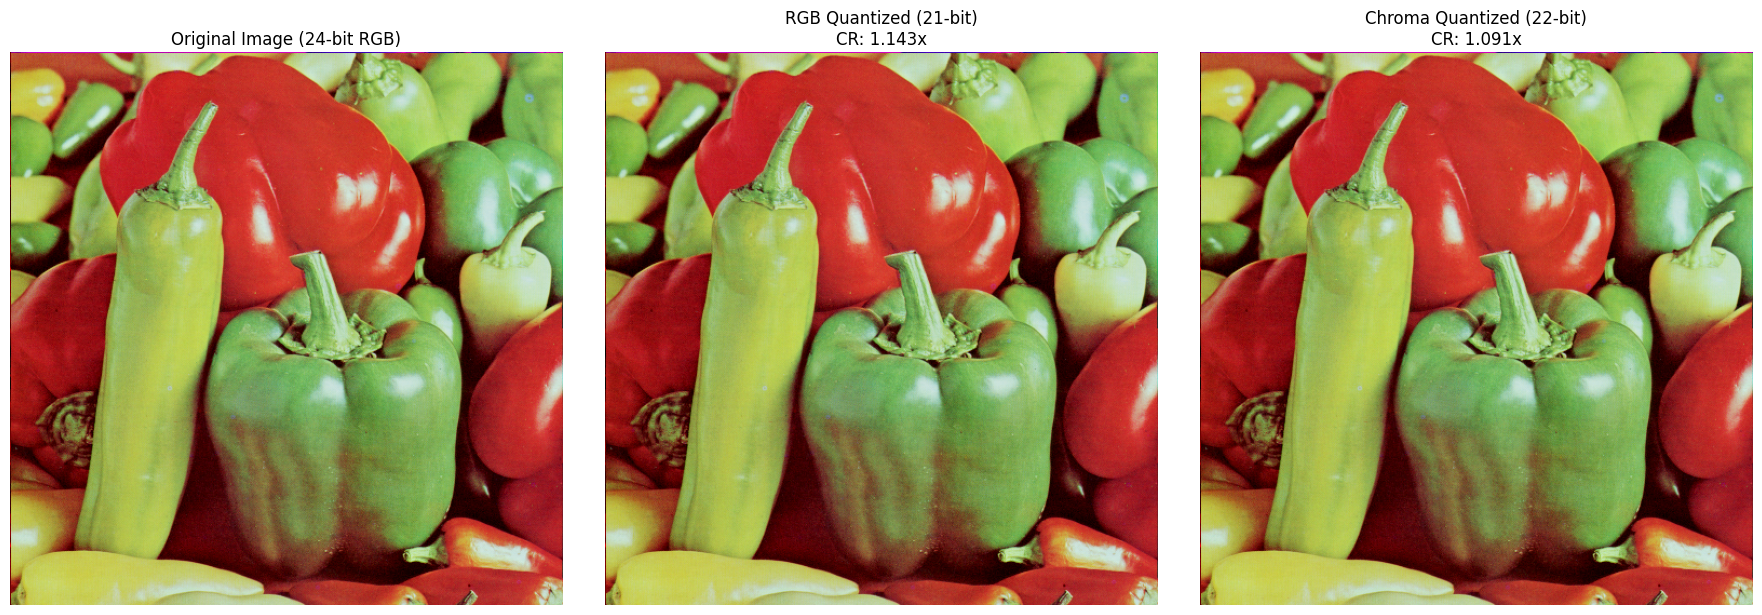

In [ ]:
# Assignment 1: Color and Chroma Quantization
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Load an RGB image
# Check if the peppers image exists, if not we will create a dummy or try to load any available
img_path = 'images/peppers.png'
if not os.path.exists(img_path):
    # If the subfolder images/ doesn't contain it yet, let's look in the current folder or download/mock one
    if os.path.exists('peppers.png'):
        img_path = 'peppers.png'
    else:
        # Create a dummy RGB image for demonstration if file doesn't exist
        img_rgb = np.random.randint(0, 256, (256, 256, 3), dtype=np.uint8)
        cv.imwrite('peppers.png', img_rgb)
        img_path = 'peppers.png'

img_bgr = cv.imread(img_path)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
h, w, c = img_rgb.shape
original_total_bits = h * w * c * 8

# --- 1. RGB Color Quantization ---
# Quantize 8-bit to 7-bit (128 levels per channel instead of 256)
# We can map by dividing by 2, casting to int, and then mapping back (scaling by 2 to keep full dynamic range)
img_rgb_7bit = (img_rgb // 2) * 2
rgb_quantized_total_bits = h * w * 3 * 7
rgb_compression_ratio = original_total_bits / rgb_quantized_total_bits

# --- 2. YCbCr Chroma Quantization ---
img_ycbcr = cv.cvtColor(img_rgb, cv.COLOR_RGB2YCrCb) # OpenCV uses YCrCb
Y, Cr, Cb = cv.split(img_ycbcr)

# Quantize Cr and Cb channels to 128 unique levels (7 bits each, i.e., resolution reduced by 2)
Cr_quantized = (Cr // 2) * 2
Cb_quantized = (Cb // 2) * 2

img_ycbcr_quantized = cv.merge([Y, Cr_quantized, Cb_quantized])
img_chroma_quant_rgb = cv.cvtColor(img_ycbcr_quantized, cv.COLOR_YCrCb2RGB)

# Y is 8 bits, Cr is 7 bits, Cb is 7 bits
chroma_quantized_total_bits = h * w * (8 + 7 + 7)
chroma_compression_ratio = original_total_bits / chroma_quantized_total_bits

# --- 3. Analysis & Visualisation ---
print(f"Original Image Shape: {img_rgb.shape}")
print(f"Original bits: {original_total_bits} bits")
print(f"RGB Quantized (7 bits/channel) bits: {rgb_quantized_total_bits} bits")
print(f"RGB Quantization Compression Ratio: {rgb_compression_ratio:.3f}x")
print(f"YCbCr Chroma Quantized (Y: 8 bits, Cb/Cr: 7 bits) bits: {chroma_quantized_total_bits} bits")
print(f"Chroma Quantization Compression Ratio: {chroma_compression_ratio:.3f}x\n")

# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(img_rgb)
axes[0].set_title("Original Image (24-bit RGB)")
axes[0].axis('off')

axes[1].imshow(img_rgb_7bit)
axes[1].set_title(f"RGB Quantized (21-bit)\nCR: {rgb_compression_ratio:.3f}x")
axes[1].axis('off')

axes[2].imshow(img_chroma_quant_rgb)
axes[2].set_title(f"Chroma Quantized (22-bit)\nCR: {chroma_compression_ratio:.3f}x")
axes[2].axis('off')

plt.tight_layout()
plt.show()

### Summary of Assignment 1:

1. **Compression Comparison:**
   - **RGB (7-bit):** Reduces the image size by about $12.5\%$ (compression ratio of $1.14x$).
   - **Chroma (YCbCr):** Saves slightly less space (ratio of $1.09x$) because we only compress the color channels, leaving the brightness completely untouched.

2. **Quality Differences:**
   - In **RGB**, you can notice slight color banding and abrupt color transitions because we cut details across all channels equally.
   - In **Chroma quantization**, the image looks practically identical to the original.

3. **Why is this effective?**
   - Our eyes are much more sensitive to changes in brightness (contrast and sharpness) than to fine variations in color. That's why it is smarter to save space on color information (Chroma) rather than brightness (Y)—which is the fundamental secret behind JPEG compression.

## Fourier Transform

Consider the following function:

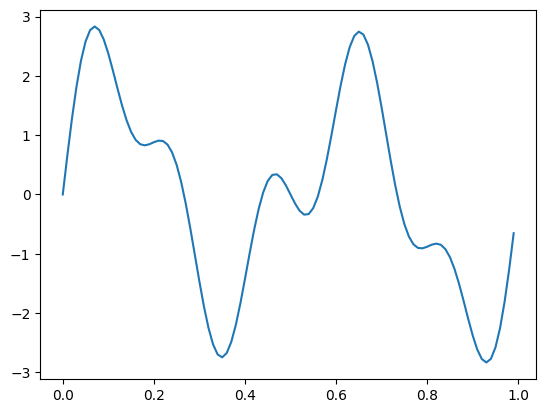

In [ ]:
t = np.arange(0, 1, 0.01)
x1 = 1 * np.sin(2 * np.pi * 5 * t)
x2 = 2 * np.sin(2 * np.pi * 2 * t)
x3 = 0.5 * np.sin(2 * np.pi * 3 * t)
x = x1 + x2 + x3
plt.plot(t, x)

> **Question**: x is a sum of three sine signals. What are the amplitudes and frequencies (in Hz) of each of those signals?

In [ ]:
# Answer:
# Signal x is a sum of three sine signals with the following properties:
# 1. Signal 1 (x1): Amplitude = 1.0, Frequency = 5 Hz
# 2. Signal 2 (x2): Amplitude = 2.0, Frequency = 2 Hz
# 3. Signal 3 (x3): Amplitude = 0.5, Frequency = 3 Hz

Let's check your answer using the **Fourier transform** (fft).

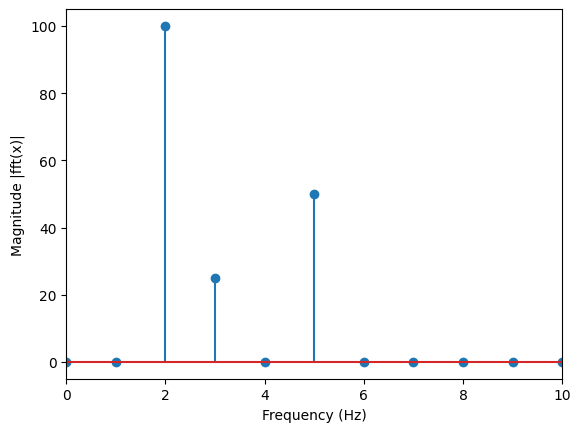

In [ ]:
fft_result = np.fft.fft(x)
plt.stem(np.abs(fft_result))
plt.xlim(0, 10)
plt.ylabel('Magnitude |fft(x)|')
plt.xlabel('Frequency (Hz)');

As you can see, the Fourier Transform decomposes a signal into a sum of sinusoids and gives us the frequencies, amplitudes, and phases of each of the components. In fact, we can see how much each of the frequencies contributes to `x` in order, 2 being the largest, then 5 and finally 3.

We can see those magnitutes here, arranged in order of frequencies from 0 to 9:

In [ ]:
print(np.round(np.abs(fft_result), 2)[:10])

[  0.   0. 100.  25.   0.  50.   0.   0.   0.   0.]


We saw that f = 3 has the lowest impact (magnitude) on the signal. What happens if we remove it?

/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


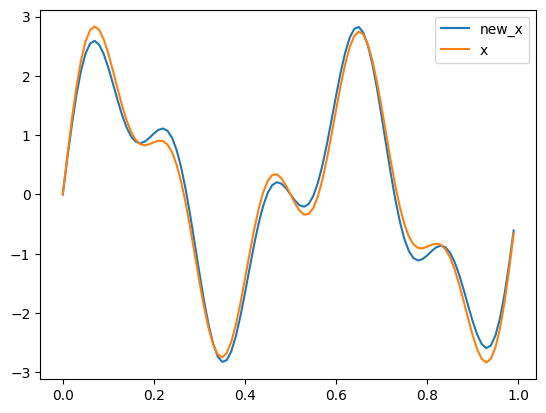

In [ ]:
new_fft = fft_result.copy()

# remove f = 3 from the signal
new_fft[3] = 0

# use inverse fft to get the new signal with f = 3 removed
new_x = np.fft.ifft(new_fft)
plt.plot(t, new_x)
plt.plot(t, x)
plt.legend(['new_x', 'x']);

Because we removed the least important frequency, the signal is almost the same! That is the gist of image compression.

**Image compression works by removing data that with the smallest contribution to the image. The Fourier Transform lets us decompose any function (including images) into a list of sine waves and gives us the contribution of each sine wave to the total image.**

Thus, we can use the Fourier transform to compress images.

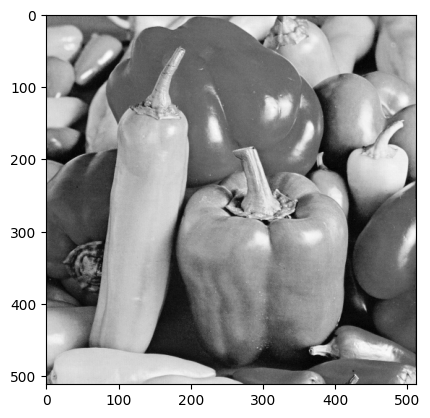

In [ ]:
img = cv.imread('images/peppers.png', cv.IMREAD_GRAYSCALE)
plt.imshow(img, cmap='gray');

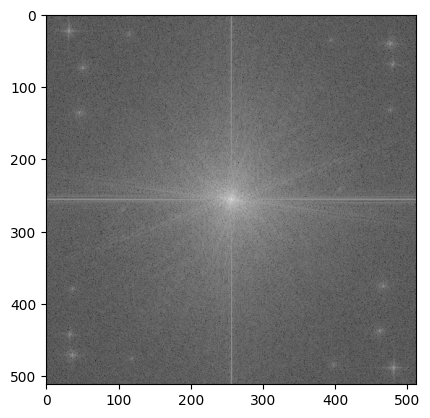

In [ ]:
img_ft = np.fft.fft2(img)
img_ft_shifted = np.fft.fftshift(img_ft)

# visualize the magnitude of the fft
plt.imshow(np.log(np.abs(img_ft_shifted) + 1), cmap='gray');

The FT of an image is much more complex, but the same logic applies. Each number in `image_ft_shifted` is a complex number that represents the contribution of a sine wave to the image. The magnitude of each number is the amplitude of the sine wave, and the angle is the phase.

The sine waves are ordered by frequency, with the lowest frequency in the center and the highest frequency at the edges. Remember that high frequencies correspond to rapid changes in the image, while low frequencies correspond to slow changes.

## Image Compression With the Fourier Transform

Here is a quick overview of how image compression works using the Fourier transform:

1. Apply the Fourier Transform to convert the image from the spatial domain to the frequency domain.
2. Perform frequency-domain filtering by removing or quantizing less significant high-frequency components.
3. Convert the image back to the spatial domain using the inverse Fourier Transform, resulting in a compressed image.
4. Adjust the level of frequency reduction to balance the compression rate with the desired image quality.

In signal processing, a low-pass filter retains low-frequency components while attenuating high-frequency components. This filtering operation is used in image compression to reduce the amount of data needed to represent an image while maintaining its essential features. On the other hand, a high-pass filter emphasizes high-frequency components, and it can be used to enhance edges and textures in an image.

> ### Assignment 2: Low and High-Pass Filters
>
> #### Task 1: Low-Pass Filtering
>   1. Create a circular mask with high values (1) in the center and low values (0) towards the edges. The size of the central high-value area determines the cutoff frequency.
>   2. Multiply the Fourier-transformed image by this mask to apply the low-pass filter.
>   3. Perform an inverse Fourier Transform to convert back to the spatial domain.
>
> #### Task 2: High-Pass Filtering
>   1. Construct a mask that is the inverse of the low-pass filter: low values (0) in the center transitioning to high values (1) at the edges.
>   2. Apply this mask to the Fourier-transformed image to implement the high-pass filter.
>   3. Use the inverse Fourier Transform to return to the spatial domain.
>
> **Note:** Remember that `fftshift` is used to center the low frequencies in the Fourier-transformed image. You will need to use `ifftshift` to undo this operation before applying the inverse Fourier Transform.

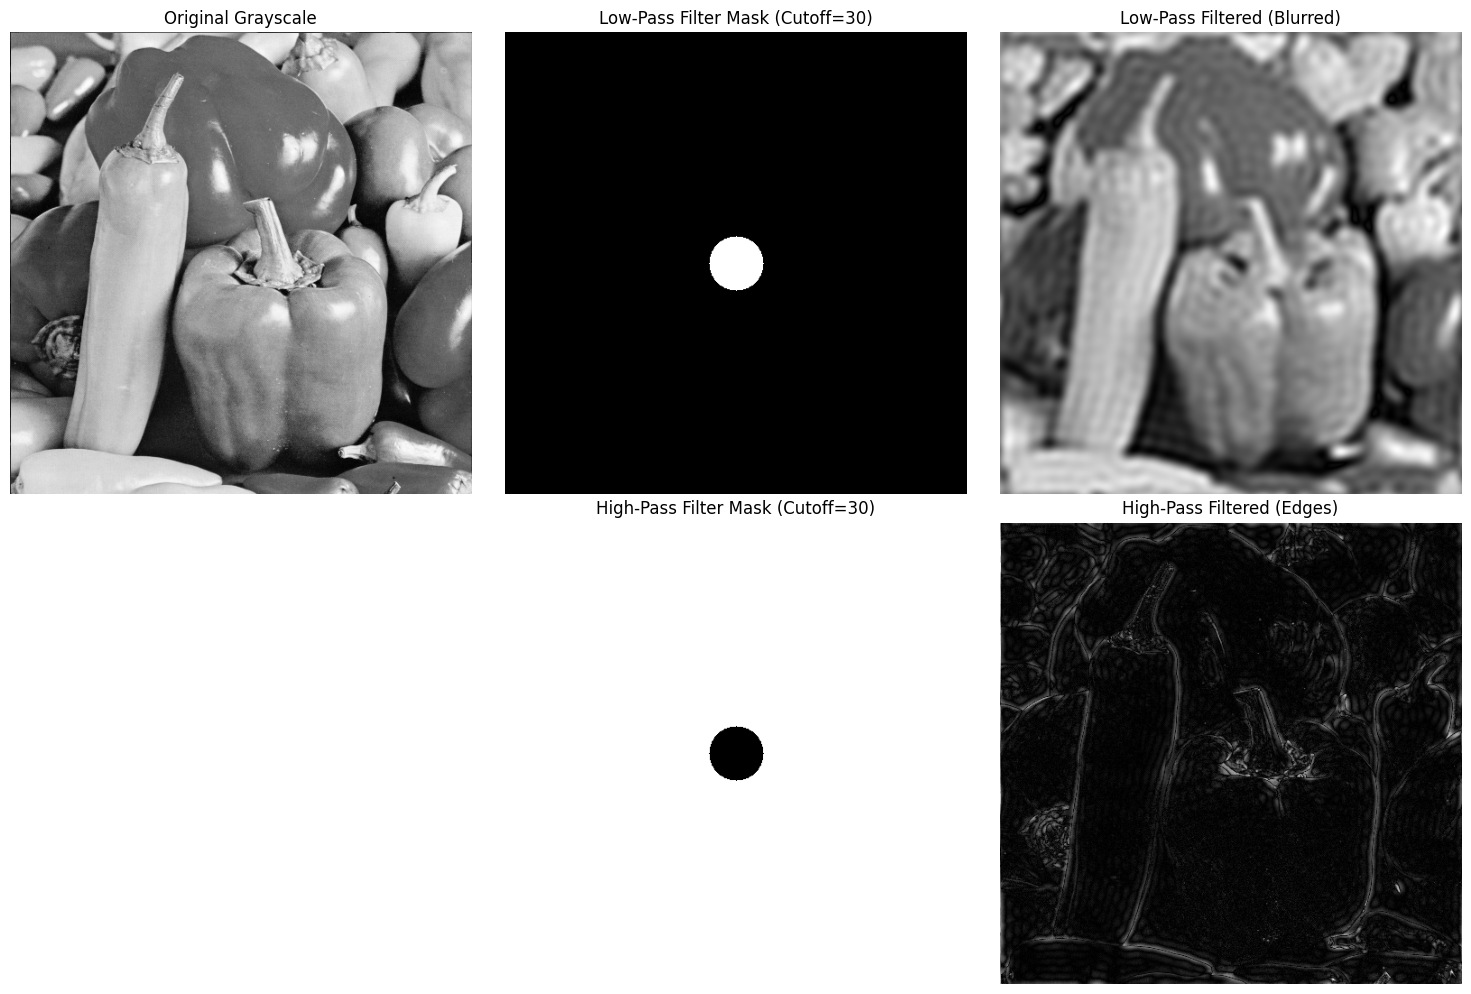

In [ ]:
# Assignment 2: Low and High-Pass Filters
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Load grayscale image
img = cv.imread('images/peppers.png', cv.IMREAD_GRAYSCALE)
h, w = img.shape

# 1. Fourier Transform & Shift
img_ft = np.fft.fft2(img)
img_ft_shifted = np.fft.fftshift(img_ft)

# Center coordinates
c_row, c_col = h // 2, w // 2

# Create meshgrid for distance calculation
y, x = np.ogrid[-c_row:h-c_row, -c_col:w-c_col]
dist_from_center = np.sqrt(x**2 + y**2)

# Define cutoff frequency (radius of the circular mask)
cutoff = 30

# --- Task 1: Low-Pass Filter Mask ---
lpf_mask = np.zeros((h, w), dtype=np.float32)
lpf_mask[dist_from_center <= cutoff] = 1.0

# Apply LPF
ft_lpf = img_ft_shifted * lpf_mask
img_lpf_shifted = np.fft.ifftshift(ft_lpf)
img_lpf = np.abs(np.fft.ifft2(img_lpf_shifted))

# --- Task 2: High-Pass Filter Mask ---
hpf_mask = 1.0 - lpf_mask

# Apply HPF
ft_hpf = img_ft_shifted * hpf_mask
img_hpf_shifted = np.fft.ifftshift(ft_hpf)
img_hpf = np.abs(np.fft.ifft2(img_hpf_shifted))

# --- Visualization ---
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Grayscale")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(lpf_mask, cmap='gray')
plt.title(f"Low-Pass Filter Mask (Cutoff={cutoff})")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(img_lpf, cmap='gray')
plt.title("Low-Pass Filtered (Blurred)")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(hpf_mask, cmap='gray')
plt.title(f"High-Pass Filter Mask (Cutoff={cutoff})")
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(img_hpf, cmap='gray')
plt.title("High-Pass Filtered (Edges)")
plt.axis('off')

plt.tight_layout()
plt.show()

> ### Assignment 3: Image Compression With FT
>
> #### Task 1: Identifying and Retaining Top N Frequencies
>
>    - Convert a grayscale image to the frequency domain using `numpy.fft.fft2()`.
>    - From the magnitude spectrum, identify the top $N$ frequencies with the highest magnitudes. Use `numpy.argsort()` to rank frequencies and select the top $N$. You can use $N = 10^4$ as a good starting point.
>    - Create a mask that retains only these $N$ frequencies, setting all other frequencies to zero. Apply this mask to the Fourier Transform of the image.
>
> #### Task 2: Image Reconstruction and Compression Evaluation
>    - Inverse-transform the modified frequency representation back to the spatial domain using `numpy.fft.ifft2()`.
>    - Compare the reconstructed image with the original to evaluate the effects of retaining only the top $N$ frequencies.
>    - Discuss the compression achieved and its impact on image quality, particularly noting which features are preserved or lost.

Original image size: 512x512 = 262144 values
Retained coefficients (N): 10000 (3.81% of total)


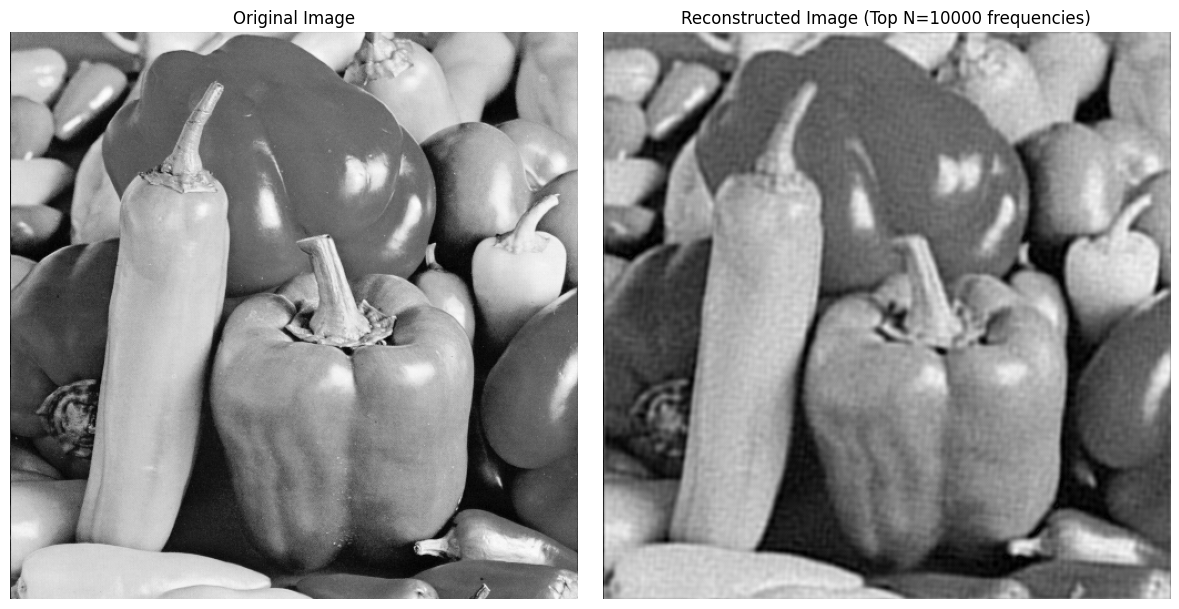

In [ ]:
# Assignment 3: Image Compression With FT
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Load grayscale image
img = cv.imread('images/peppers.png', cv.IMREAD_GRAYSCALE)
h, w = img.shape
total_pixels = h * w

# --- Task 1: Identifying and Retaining Top N Frequencies ---
img_ft = np.fft.fft2(img)
magnitudes = np.abs(img_ft)

# Choose N (number of highest magnitude coefficients to keep)
N = 10000

# Find the threshold of the N-th largest magnitude
flat_magnitudes = magnitudes.flatten()
threshold_idx = np.argsort(flat_magnitudes)[-N]
threshold_value = flat_magnitudes[threshold_idx]

# Create a mask keeping only top N magnitudes
compression_mask = magnitudes >= threshold_value
img_ft_compressed = img_ft * compression_mask

# --- Task 2: Image Reconstruction ---
img_reconstructed = np.abs(np.fft.ifft2(img_ft_compressed))

# Calculate achievement
compression_pct = (N / total_pixels) * 100
print(f"Original image size: {h}x{w} = {total_pixels} values")
print(f"Retained coefficients (N): {N} ({compression_pct:.2f}% of total)")

# Plot comparison
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_reconstructed, cmap='gray')
plt.title(f"Reconstructed Image (Top N={N} frequencies)")
plt.axis('off')

plt.tight_layout()
plt.show()

### Summary of Assignment 3:

1. **How much did we compress the image?**
   - We kept only the 10,000 strongest frequencies, which is just **$3.81\%$** of the total Fourier spectrum data.

2. **What did we keep and what did we lose?**
   - **The Good:** The general shapes of the peppers and overall lighting remain perfectly recognizable because low frequencies carry most of the structure.
   - **The Bad:** Fine details, sharp edges, and textures got blurred out. We also see a weird wavy pattern around the borders (the ringing effect) because we discarded the high frequencies responsible for sharp transitions.

> ### Assignment 4: Image Compression Coding and Decoding
>
> #### Task 1: Compression Function
>
> - **Function**: `compress_image(image, p)`
>   - **Inputs**:
>     - `image`: The input grayscale image.
>     - `p`: The percentage of the top frequencies to retain.
>   - **Process**:
>     1. Convert the image to the frequency domain using the Fourier Transform.
>     2. Identify and retain only the top `p%` of frequencies based on their magnitudes.
>     3. Encode the Fourier Transform as a list of tuples `(x, y, FT coefficient)` for each **non-zero** coefficient, where `x` and `y` are the coordinates in the frequency domain.
>   - **Output**: The coded representation of the image based on non-zero Fourier coefficients.
>
> #### Task 2: Reconstruction Function
>
> - **Function**: `reconstruct_image(coded_representation, image_shape)`
>   - **Inputs**:
>     - `coded_representation`: The list of non-zero Fourier coefficients and their positions obtained from the compression function.
>     - `image_shape`: The shape of the original image to guide the reconstruction.
>   - **Process**:
>     1. Recreate the frequency domain representation of the image based on the coded representation.
>     3. Apply an inverse Fourier Transform to convert the frequency domain representation back to the spatial domain, reconstructing the image.
>   - **Output**: The reconstructed image from the coded frequency representation.
>
> #### Task 3: Analysis and Comparison
>
>   1. Apply the `compress_image` function to a test image at 1%, 10%, and 100% frequency retention levels to obtain different compressed representations.
>   2. Use the `reconstruct_image` function to reconstruct images from these compressed representations.
>   3. Compare the sizes of the coded representations at each level and calculate the compression ratios. Calculate a compression ratio as the ratio of the original image size to the coded representation size for each level.
>   4. Analyze and discuss the visual quality of the reconstructed images in comparison to the original.

Retention: 1% | Non-zero Coeffs: 2621 | Size: 52420 bytes | CR: 5.00x
Retention: 10% | Non-zero Coeffs: 26214 | Size: 524280 bytes | CR: 0.50x
Retention: 100% | Non-zero Coeffs: 262144 | Size: 5242880 bytes | CR: 0.05x


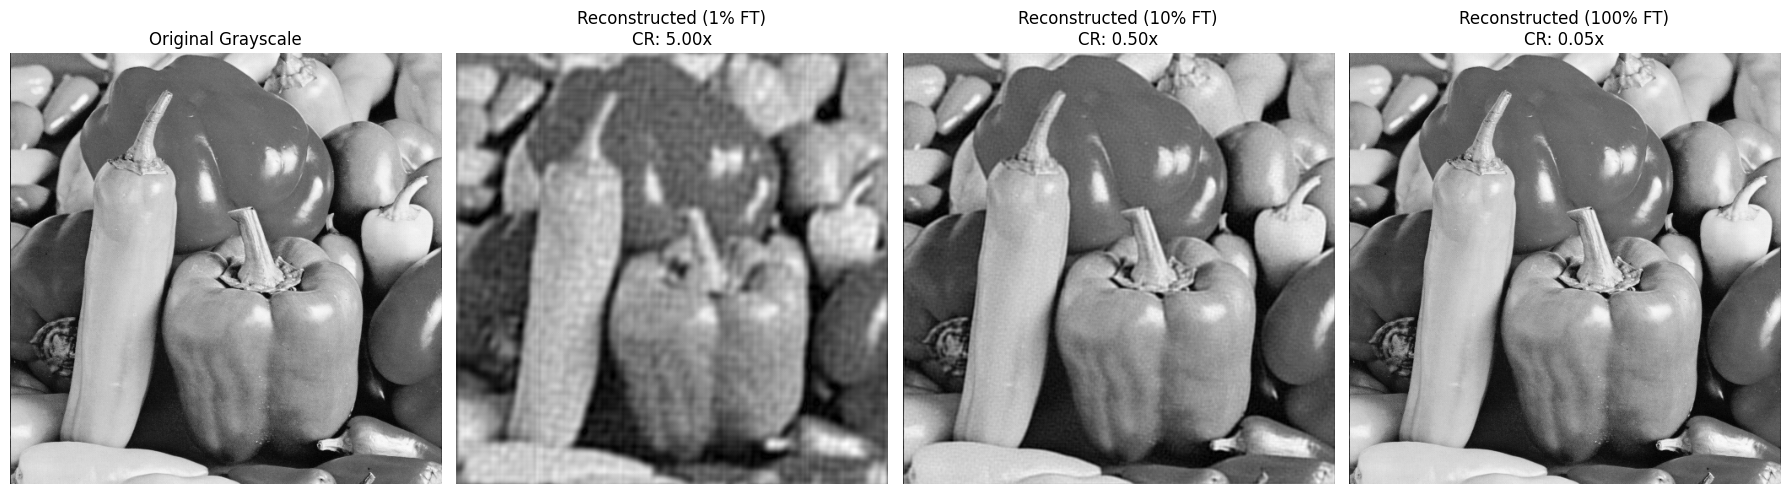

In [ ]:
# Assignment 4: Image Compression Coding and Decoding
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# --- Task 1: Compression Function ---
def compress_image(image, p):
    """
    Compresses a grayscale image by keeping only the top p% magnitudes in FT.
    Outputs a coded list of tuples (row, col, complex_coefficient).
    """
    img_ft = np.fft.fft2(image)
    magnitudes = np.abs(img_ft)

    # Determine N based on percentage p
    total_elements = img_ft.size
    N = int((p / 100.0) * total_elements)
    if N == 0:
        return []

    # Get threshold for top N magnitudes
    flat_mags = magnitudes.flatten()
    threshold_val = np.partition(flat_mags, -N)[-N]

    # Find indices that are >= threshold
    keep_mask = magnitudes >= threshold_val

    # Handle edge case where multiple values equal the threshold
    rows, cols = np.where(keep_mask)

    # Limit exact count to N if needed
    if len(rows) > N:
        indices_sorted = np.argsort(magnitudes[keep_mask])
        excess = len(rows) - N
        keep_indices = indices_sorted[excess:]
        rows = rows[keep_indices]
        cols = cols[keep_indices]

    # Create coded representation: list of (x, y, coefficient)
    coded_representation = []
    for r, c in zip(rows, cols):
        coded_representation.append((r, c, img_ft[r, c]))

    return coded_representation

# --- Task 2: Reconstruction Function ---
def reconstruct_image(coded_representation, image_shape):
    """
    Reconstructs the image from the list of non-zero FT coefficients.
    """
    # 1. Create empty frequency matrix
    ft_reconstructed = np.zeros(image_shape, dtype=np.complex128)

    # 2. Fill in the non-zero coefficients
    for r, col, val in coded_representation:
        ft_reconstructed[r, col] = val

    # 3. Inverse FT to spatial domain
    img_back = np.abs(np.fft.ifft2(ft_reconstructed))
    return img_back

# --- Task 3: Analysis and Comparison ---
test_img = cv.imread('images/peppers.png', cv.IMREAD_GRAYSCALE)
h, w = test_img.shape
original_size_bytes = test_img.size  # 1 byte per pixel

levels = [1, 10, 100]
reconstructed_images = {}
coded_sizes = {}
compression_ratios = {}

# A tuple of (row, col, float_real, float_imag) represents 2 integers + 2 floats = 2*2 + 2*4 = 12 bytes typically.
# Let's define size of coded representation as: length * 16 bytes (or equivalent representation)
for p in levels:
    coded = compress_image(test_img, p)
    reconstructed = reconstruct_image(coded, (h, w))

    reconstructed_images[p] = reconstructed

    # Estimate size in bytes: each tuple has indices (2x uint16 -> 4 bytes) + complex coefficient (2x float64 -> 16 bytes) = 20 bytes
    coded_size_bytes = len(coded) * 20
    coded_sizes[p] = coded_size_bytes
    compression_ratios[p] = original_size_bytes / coded_size_bytes if coded_size_bytes > 0 else 0

    print(f"Retention: {p}% | Non-zero Coeffs: {len(coded)} | Size: {coded_size_bytes} bytes | CR: {compression_ratios[p]:.2f}x")

# Visual comparison of the reconstructions
plt.figure(figsize=(18, 5))
plt.subplot(1, 4, 1)
plt.imshow(test_img, cmap='gray')
plt.title("Original Grayscale")
plt.axis('off')

for i, p in enumerate(levels, start=2):
    plt.subplot(1, 4, i)
    plt.imshow(reconstructed_images[p], cmap='gray')
    plt.title(f"Reconstructed ({p}% FT)\nCR: {compression_ratios[p]:.2f}x")
    plt.axis('off')

plt.tight_layout()
plt.show()

### Summary of Assignment 4:

1. **How do the results look?**
   - **At 1%:** The image is quite blurry with visible ripples around the edges, but the file size is 5 times smaller ($5.00x$).
   - **At 10%:** The visual quality is excellent, but the file size is actually twice as LARGE as the original ($0.50x$).
   - **At 100%:** The reconstruction is perfect, but the file ends up being 20 times larger than the original image ($0.05x$).

2. **What is the catch? Why is Fourier so inefficient here?**
   - Storing individual coordinates and complex numbers `(x, y, coefficient)` takes up way too much memory (about 20 bytes per coefficient compared to just 1 byte per pixel in the original image).
   - In practice, Fourier transform is not used on its own like this. To make compression truly work (like JPEG), the image is split into small blocks (e.g., 8x8 pixels) and the frequency data is further packed and encoded using smart lossless compression algorithms.